# 11 · Validation cohort (GSE136831): loading, QC, normalisation and integration

A finding from one cohort may reflect that cohort's donors, tissue handling,
chemistry or analysis choices. The strongest test is **replication in an
independent cohort**. Adams *et al.* 2020 profiled 28 control and 32 IPF lungs
at Yale/Brigham and Women's with 10x 3′ v2 chemistry - a different centre,
chemistry (3′ vs 5′) and processing pipeline - which makes concordant results
hard to explain by technical artefacts.

The same processing logic as the discovery cohort is applied. The GEO matrix
was already filtered by the authors (≥1,000 UMIs per cell, multiplets
annotated), so we remove the authors' multiplets, exclude COPD donors (not part
of our question) and apply our mitochondrial and gene/UMI floors.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

from ipfatlas import features, integration, io, qc
from ipfatlas.config import setup
from ipfatlas.plotting import CONDITION_COLORS, embedding_scatter, figsize, palette_for, panel_label, save_figure, set_style
from ipfatlas.utils import write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "11_validation"
TAB = P.tables / "11_validation"
QC = cfg["qc"]

In [2]:
adata = io.read_adams(P.raw)
adata = adata[adata.obs["diagnosis"].isin(["Control", "IPF"]) & (adata.obs["author_celltype"] != "Multiplet")].copy()
for c in adata.obs.select_dtypes("category"):
    adata.obs[c] = adata.obs[c].cat.remove_unused_categories()
adata

02:51:37 | INFO | reading GSE136831_RawCounts_Sparse.mtx.gz ...


02:52:06 | INFO | reading GSE136831_RawCounts_Sparse.mtx.gz done in 29.9 s


02:52:43 | INFO | Adams: 312,928 cells x 45,947 genes, 78 donors


AnnData object with n_obs × n_vars = 239707 × 45947
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_subclass', 'author_compartment', 'harmonised_celltype', 'cohort', 'chemistry'
    var: 'gene_ids', 'gene_symbol'

## 1. QC

In [3]:
qc.compute_qc_metrics(adata, layer=None)
thr = qc.flag_outliers(adata, QC, groupby="library_id")
write_table(thr.round(2), TAB / "validation_qc_thresholds_per_library")
print(adata.obs[["outlier_counts", "outlier_genes", "outlier_top20", "outlier_mito", "outlier_hard", "qc_fail"]].sum())

outlier_counts      667
outlier_genes       947
outlier_top20      1895
outlier_mito      11264
outlier_hard         54
qc_fail           12273
dtype: int64


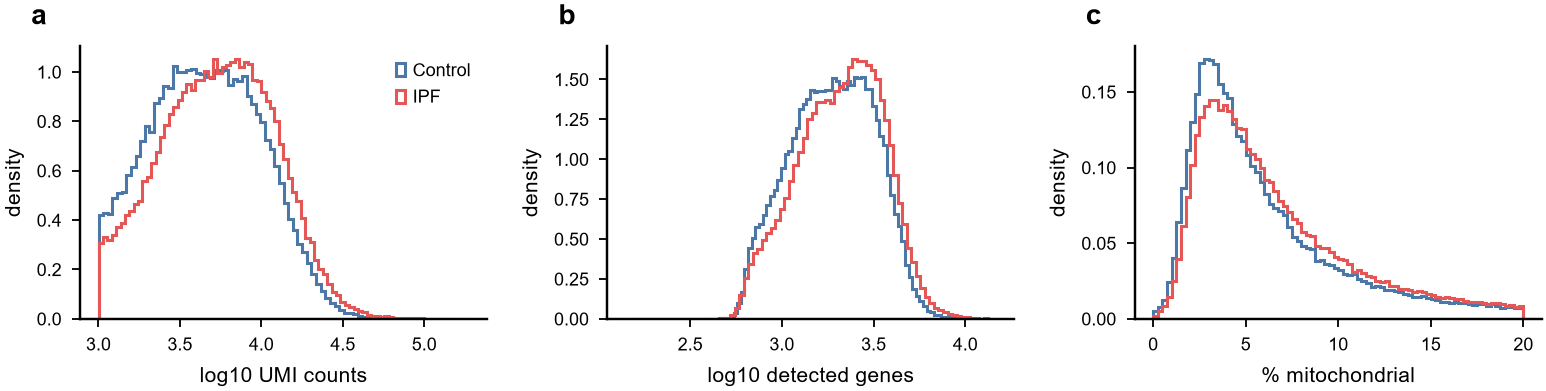

In [4]:
fig, axes = plt.subplots(1, 3, figsize=figsize(183, 50))
for ax, col, lab in zip(axes, ["total_counts", "n_genes_by_counts", "pct_counts_mt"],
                        ["UMI counts", "detected genes", "% mitochondrial"]):
    for dx in ["Control", "IPF"]:
        v = adata.obs.loc[adata.obs["diagnosis"] == dx, col]
        ax.hist(np.log10(v + 1) if col != "pct_counts_mt" else v, bins=80, histtype="step",
                color=CONDITION_COLORS[dx], label=dx, density=True)
    ax.set_xlabel(("log10 " if col != "pct_counts_mt" else "") + lab)
    ax.set_ylabel("density")
axes[0].legend()
for a, l in zip(axes, "abc"):
    panel_label(a, l)
fig.tight_layout()
save_figure(fig, "S11_validation_qc_distributions", FIG)
plt.show()

In [5]:
n0 = adata.n_obs
adata = adata[~adata.obs["qc_fail"]].copy()
sc.pp.filter_genes(adata, min_cells=QC["min_cells_per_gene"])
adata.layers["counts"] = adata.X.copy()
print(f"{n0:,} -> {adata.n_obs:,} cells; {adata.n_vars:,} genes")

239,707 -> 227,434 cells; 37,953 genes


## 2. Donor sex

In [6]:
sex = qc.infer_sex(adata, donor_key="donor_id", layer="counts")
sex["diagnosis"] = adata.obs.groupby("donor_id", observed=True)["diagnosis"].first()
write_table(sex, TAB / "validation_inferred_sex")
adata.obs["sex"] = adata.obs["donor_id"].map(sex["inferred_sex"]).astype("category")
pd.crosstab(sex["diagnosis"], sex["inferred_sex"])

inferred_sex,female,male
diagnosis,,
Control,10,18
IPF,7,25


## 3. Normalisation, HVGs and scVI integration (batch = library)

In [7]:
sc.pp.normalize_total(adata, target_sum=None)
sc.pp.log1p(adata)
adata.layers["log1p_norm"] = adata.X.copy()
hvg = features.select_hvgs(adata, cfg["features"], batch_key="library_id")

hv = adata[:, adata.var["highly_variable"]].copy()
model = integration.train_scvi(hv, "library_id", cfg["integration"]["scvi"], layer="counts",
                               save_dir=P.processed / "models" / "scvi_validation")
adata.obsm["X_scVI"] = model.get_latent_representation()
del hv
sc.pp.neighbors(adata, use_rep="X_scVI", n_neighbors=15, random_state=0)
sc.tl.umap(adata, min_dist=0.3, random_state=0)

02:53:36 | INFO | HVG selection: 855 nuisance genes excluded; 79/83 batches with >= 500 cells vote


02:53:48 | WARNING | loess failed with span=0.3 (b'reciprocal condition number  1.489e-14'); retrying with a wider span


W1029 02:54:08.597000 58652 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Seed set to 0


02:54:10 | INFO | scVI training ...


GPU available: True (cuda), used: True


... (3 outputs left out)

J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Training:   0%|          | 0/300 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=300` reached.


03:10:27 | INFO | scVI training done in 976.6 s


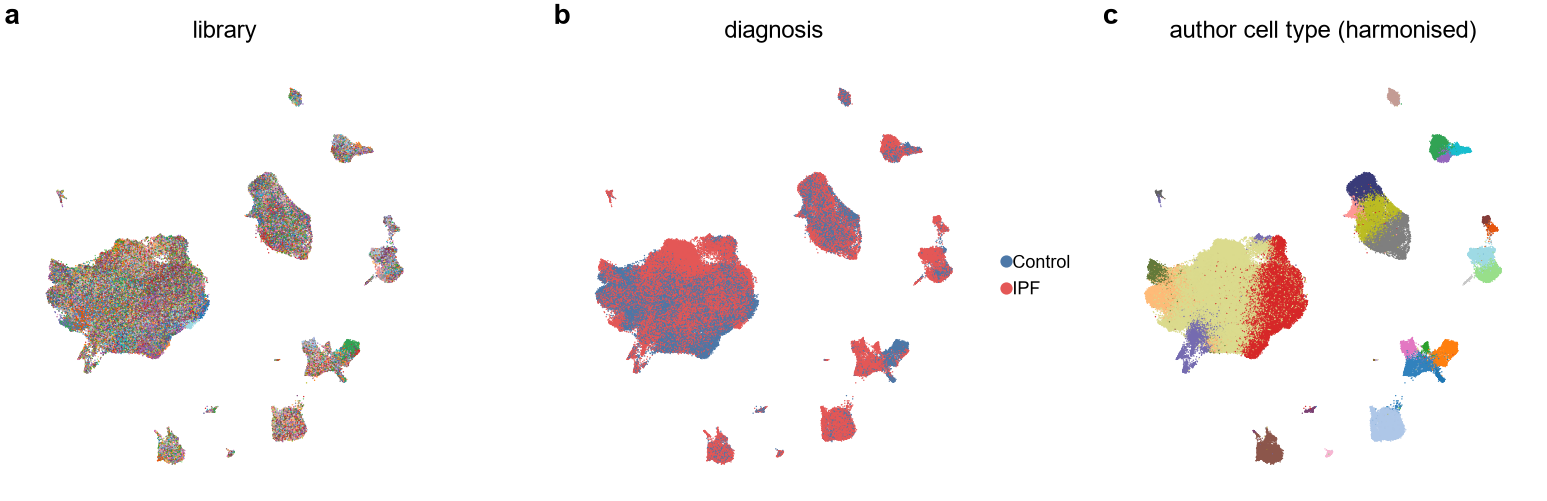

In [8]:
fig, axes = plt.subplots(1, 3, figsize=figsize(183, 62))
xy = adata.obsm["X_umap"]
embedding_scatter(axes[0], xy, adata.obs["library_id"], s=0.2)
axes[0].set_title("library")
embedding_scatter(axes[1], xy, adata.obs["diagnosis"], palette=CONDITION_COLORS, s=0.2, legend=True)
axes[1].set_title("diagnosis")
embedding_scatter(axes[2], xy, adata.obs["harmonised_celltype"], s=0.2)
axes[2].set_title("author cell type (harmonised)")
for a, l in zip(axes, "abc"):
    panel_label(a, l, x=0.0)
fig.tight_layout()
save_figure(fig, "S11_validation_umap_overview", FIG)
plt.show()

In [9]:
summary = adata.obs.groupby("diagnosis", observed=True).agg(donors=("donor_id", "nunique"),
                                                           libraries=("library_id", "nunique"),
                                                           cells=("donor_id", "size"))
write_table(summary, TAB / "validation_cohort_summary")
adata.X = adata.layers["log1p_norm"]
del adata.layers["log1p_norm"]  # .X holds it; keeps the file smaller
adata.write_h5ad(P.processed / "validation_processed.h5ad", compression="lzf")
summary

,donors,libraries,cells
diagnosis,,,
Control,28,38,90832
IPF,32,45,136602
